# Tipo de delito por zona-turno (issue #22)

**Proyecto integrador de tecnologías de Big Data** · Predicción de delitos en Chicago · Valentino De Paola, Eduardo López y Carlos David González

La pregunta del proyecto es **dónde, cuándo y qué tipo** de delito es más probable. Los modelos de conteo (Fase 3 y #21) responden dónde y cuándo; este notebook responde **qué tipo**.

**Qué se predice.** Para cada incidente, su tipo según dónde y cuándo ocurrió. No se predice "el tipo más frecuente de la semana" de cada zona-turno porque con una mediana de 4 incidentes por zona-turno a la semana ese objetivo empata en el 38 % de los casos. Las probabilidades del modelo, juntas por zona-turno, dicen qué mezcla de delitos esperar ahí ("30 % robos, 25 % agresiones"), que es lo que le sirve a una patrulla para saber a qué va.

**Clases.** Los 6 tipos más frecuentes y OTROS. NARCOTICS y WEAPONS VIOLATION quedan fuera, igual que en la Fase 3: los detecta la propia patrulla y miden dónde se patrulla más que dónde ocurren.

**Variables.** Solo lo que se sabe antes del incidente: la mezcla de tipos de esa zona-turno en las 52 semanas anteriores y cuántos incidentes tuvo, el turno, el día de la semana, la semana del año y el distrito. No se usan el lugar ni la descripción del incidente, porque se conocen hasta que ya ocurrió.

**División.** La de la Fase 3: prueba con las semanas 42 a 51 de 2025 y entrenamiento con todo lo anterior. La mezcla de 52 semanas pide un año de historia, así que los incidentes de 2022 solo sirven como historia.

**Cómo correrlo:** en la instancia, con `LOCAL = False`, *Kernel → Restart Kernel and Run All Cells*. Antes tiene que haber corrido `fase3_pipeline.ipynb` con los cuatro años, que deja `chicago.crimes_2022_2025` y `chicago.zona_turno_2022_2025`.

## Configuración

In [1]:
LOCAL = False                 # False: instancia (HDFS + YARN) · True: prueba en una compu con los datos locales

PRIMER_ANIO, ANIO_PRUEBA = 2022, 2025
SEMANA_CORTE, SEMANA_VALIDACION = 42, 34   # del último año: 42 a 51 prueban, 34 a 41 validan, como en la Fase 3
HISTORIA = 52                              # semanas de historia para la mezcla de tipos
ETIQUETA = f"{PRIMER_ANIO}_{ANIO_PRUEBA}"

RUTA_DATALAKE = "../data" if LOCAL else "hdfs:///datalake"
RUTA_CRIMENES = f"{RUTA_DATALAKE}/processed/crimes_{ETIQUETA}"
TABLA_CRIMENES = f"chicago.crimes_{ETIQUETA}"
RUTA_ZONA_TURNO = f"{RUTA_DATALAKE}/curated/zona_turno_{ETIQUETA}"
TABLA_ZONA_TURNO = f"chicago.zona_turno_{ETIQUETA}"
RUTA_SALIDA = f"{RUTA_DATALAKE}/curated/tipo_delito_{ETIQUETA}"
TABLA_SALIDA = f"chicago.tipo_delito_{ETIQUETA}"          # un incidente por fila, con sus variables y su clase
RUTA_METRICAS = f"{RUTA_DATALAKE}/curated/metricas_tipo_delito_{ETIQUETA}"

In [2]:
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.feature import OneHotEncoder, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession, Window, functions as F

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

builder = (SparkSession.builder
           .appName(f"tipo-de-delito-{'local' if LOCAL else 'cluster'}")
           .config("spark.sql.session.timeZone", "UTC"))
if LOCAL:
    spark = (builder.master("local[*]").config("spark.driver.memory", "4g")
             .config("spark.ui.showConsoleProgress", "false").getOrCreate())
else:
    spark = builder.enableHiveSupport().getOrCreate()   # master = yarn (spark-defaults.conf)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| master:", spark.sparkContext.master)

CARPETA_FIGURAS = Path("figuras")
CARPETA_FIGURAS.mkdir(exist_ok=True)


def guardar(fig, nombre):
    """Guarda la figura como PNG en notebooks/figuras/ para el reporte."""
    ruta = CARPETA_FIGURAS / f"T_{nombre}_{'local' if LOCAL else 'cluster'}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada en", ruta)


def a_semana_global(anio, semana):
    """Número de semana contado desde la semana 0 de 2022 (52 semanas por año), igual que en A3."""
    return (anio - PRIMER_ANIO) * 52 + semana


CORTE_GLOBAL = a_semana_global(ANIO_PRUEBA, SEMANA_CORTE)
VALIDACION_GLOBAL = a_semana_global(ANIO_PRUEBA, SEMANA_VALIDACION)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 01:36:33 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master: yarn


## 1. Incidentes y clases

Mismas exclusiones que A3 de la Fase 3: hora imputada (no se sabe su turno), NARCOTICS y WEAPONS VIOLATION, el beat 6100 y el 31 de diciembre. Solo entran los beats de la tabla zona-turno, que son los que aparecen en los cuatro años.

In [3]:
if LOCAL:
    crimenes = spark.read.parquet(RUTA_CRIMENES)
    beats = spark.read.parquet(RUTA_ZONA_TURNO).select("beat", "district").distinct()
else:
    crimenes = spark.table(TABLA_CRIMENES)
    beats = spark.table(TABLA_ZONA_TURNO).select("beat", "district").distinct()

TIPOS_SESGO_PATRULLAJE = ["NARCOTICS", "WEAPONS VIOLATION"]
TURNOS = {0: "00-06", 1: "06-12", 2: "12-18", 3: "18-24"}
DIAS = {2: "Lun", 3: "Mar", 4: "Mié", 5: "Jue", 6: "Vie", 7: "Sáb", 1: "Dom"}   # dia_semana: 1 = domingo

incidentes = (crimenes
              .filter(~F.col("hora_imputada") & ~F.col("primary_type").isin(TIPOS_SESGO_PATRULLAJE))
              .join(beats.select("beat"), "beat", "left_semi")
              .withColumn("semana", F.floor((F.dayofyear("fecha") - 1) / 7).cast("int"))
              .filter("semana < 52")
              .withColumn("semana_global", a_semana_global(F.col("anio"), F.col("semana")).cast("int"))
              .withColumn("turno", F.floor(F.col("hora") / 6).cast("int"))
              .select("id", "beat", "turno", "anio", "semana", "semana_global", "dia_semana", "primary_type"))

# Las clases salen del entrenamiento: los 6 tipos más frecuentes antes de la prueba
frecuencias = (incidentes.filter(F.col("semana_global") < CORTE_GLOBAL)
               .groupBy("primary_type").count().orderBy(F.desc("count")).toPandas())
CLASES = list(frecuencias["primary_type"].head(6)) + ["OTROS"]
INDICE = {c: i for i, c in enumerate(CLASES)}

incidentes = (incidentes
              .withColumn("clase", F.when(F.col("primary_type").isin(CLASES[:-1]), F.col("primary_type")).otherwise("OTROS"))
              .withColumn("label", F.create_map(*[F.lit(x) for c, i in INDICE.items() for x in (c, i)])[F.col("clase")].cast("double"))
              .cache())
n_incidentes = incidentes.count()

reparto = (incidentes.groupBy("clase").count().toPandas().set_index("clase").reindex(CLASES))
reparto["%"] = (reparto["count"] * 100 / n_incidentes).round(1)
print(f"{n_incidentes:,} incidentes de {PRIMER_ANIO} a {ANIO_PRUEBA} · {len(CLASES)} clases")
reparto

879,488 incidentes de 2022 a 2025 · 7 clases


,count,%
clase,,
THEFT,212442,24.2
BATTERY,167999,19.1
CRIMINAL DAMAGE,105311,12.0
ASSAULT,85216,9.7
MOTOR VEHICLE THEFT,83657,9.5
OTHER OFFENSE,58793,6.7
OTROS,166070,18.9


## 2. Variables

### 2.1 Mezcla de tipos de la zona-turno en el último año

Para cada zona-turno y cada semana se cuentan los incidentes de cada clase en las 52 semanas **anteriores** (`rowsBetween(-52, -1)`, igual que en la Fase 3) y se convierten en porcentajes: `mezcla_THEFT`, `mezcla_BATTERY`, etc. También queda el total de esas 52 semanas, `incidentes_52`, porque una mezcla de 10 incidentes es menos confiable que una de 500.

Se arma primero la malla completa (zona-turno × semana × clase, con ceros), para que retrasar filas sea retrasar semanas.

In [4]:
zonas = beats.select("beat").crossJoin(spark.createDataFrame([(t,) for t in TURNOS], "turno int"))
semanas = spark.range(52 * (ANIO_PRUEBA - PRIMER_ANIO + 1)).select(F.col("id").cast("int").alias("semana_global"))
clases = spark.createDataFrame([(c,) for c in CLASES], "clase string")

conteos = incidentes.groupBy("beat", "turno", "semana_global", "clase").agg(F.count("*").alias("n"))
malla = (zonas.crossJoin(semanas).crossJoin(clases)
         .join(conteos, ["beat", "turno", "semana_global", "clase"], "left")
         .fillna(0, ["n"]))

por_zona_clase = Window.partitionBy("beat", "turno", "clase").orderBy("semana_global").rowsBetween(-HISTORIA, -1)
historia = (malla
            .withColumn("n_52", F.sum("n").over(por_zona_clase))
            .withColumn("semanas_vistas", F.count("n").over(por_zona_clase))
            .filter(F.col("semanas_vistas") == HISTORIA)
            .groupBy("beat", "turno", "semana_global")
            .pivot("clase", CLASES).agg(F.first("n_52")))

MEZCLA = [f"mezcla_{c.replace(' ', '_')}" for c in CLASES]
historia = historia.withColumn("incidentes_52", sum(F.col(f"`{c}`") for c in CLASES))
historia = historia.select("beat", "turno", "semana_global", "incidentes_52",
                           *[F.when(F.col("incidentes_52") > 0, F.col(f"`{c}`") / F.col("incidentes_52")).otherwise(0.0).alias(m)
                             for c, m in zip(CLASES, MEZCLA)])

### 2.2 Cuándo y dónde

El turno y el día de la semana entran como categorías; la semana del año como seno y coseno (igual que en el #21); el distrito, como categoría.

In [5]:
angulo = 2 * math.pi * F.col("semana") / 52
datos = (incidentes
         .join(historia, ["beat", "turno", "semana_global"])   # solo incidentes con un año completo de historia
         .join(beats, "beat")
         .withColumn("turno_etiqueta", F.create_map(*[F.lit(x) for k, v in TURNOS.items() for x in (k, v)])[F.col("turno")])
         .withColumn("dia", F.create_map(*[F.lit(x) for k, v in DIAS.items() for x in (k, v)])[F.col("dia_semana")])
         .withColumn("semana_seno", F.sin(angulo))
         .withColumn("semana_coseno", F.cos(angulo))
         .withColumn("conjunto", F.when(F.col("semana_global") < CORTE_GLOBAL, "entrenamiento").otherwise("prueba")))

# Regla simple: el tipo con más peso en la mezcla del último año (empates: el tipo más común de la ciudad, que va primero)
mezcla_arr = F.array(*[F.col(m) for m in MEZCLA])
datos = datos.withColumn("regla_zona_turno", F.array_position(mezcla_arr, F.array_max(mezcla_arr)).cast("double") - 1)

### 2.3 Verificación a mano

Se toma el beat con más incidentes, el turno de 12 a 18 y la semana 30 de 2025, y se recuenta la mezcla directo de los incidentes, sin malla ni ventanas.

In [6]:
beat_ej = incidentes.groupBy("beat").count().orderBy(F.desc("count")).first()["beat"]
turno_ej, semana_ej = 2, a_semana_global(ANIO_PRUEBA, 30)

previos = (incidentes.filter((F.col("beat") == beat_ej) & (F.col("turno") == turno_ej)
                             & F.col("semana_global").between(semana_ej - HISTORIA, semana_ej - 1))
           .groupBy("clase").count().toPandas().set_index("clase")["count"].reindex(CLASES, fill_value=0))
fila = historia.filter((F.col("beat") == beat_ej) & (F.col("turno") == turno_ej) & (F.col("semana_global") == semana_ej)).first()

assert fila["incidentes_52"] == previos.sum()
for clase, columna in zip(CLASES, MEZCLA):
    assert abs(fila[columna] - previos[clase] / previos.sum()) < 1e-9, clase
print(f"Beat {beat_ej}, turno 12-18, semana 30 de {ANIO_PRUEBA}: {previos.sum()} incidentes en las 52 semanas anteriores ✔")
pd.DataFrame({"contados a mano": previos, "mezcla (%)": [round(fila[m] * 100, 1) for m in MEZCLA]})

Beat 1834, turno 12-18, semana 30 de 2025: 1135 incidentes en las 52 semanas anteriores ✔


,contados a mano,mezcla (%)
clase,,
THEFT,595,52.4
BATTERY,112,9.9
CRIMINAL DAMAGE,48,4.2
ASSAULT,60,5.3
MOTOR VEHICLE THEFT,23,2.0
OTHER OFFENSE,35,3.1
OTROS,262,23.1


### 2.4 Guardar y dividir

In [7]:
NUMERICAS = MEZCLA + ["incidentes_52", "semana_seno", "semana_coseno"]
CATEGORICAS = ["turno_etiqueta", "dia", "district"]
COLUMNAS = ["id", "beat", "district", "turno", "turno_etiqueta", "anio", "semana", "semana_global", "dia",
            *NUMERICAS, "regla_zona_turno", "clase", "label", "conjunto"]

df_salida = datos.select(COLUMNAS).coalesce(4)
if LOCAL:
    df_salida.write.mode("overwrite").parquet(RUTA_SALIDA)
    tabla = spark.read.parquet(RUTA_SALIDA)
else:
    df_salida.write.mode("overwrite").format("parquet").option("path", RUTA_SALIDA).saveAsTable(TABLA_SALIDA)
    tabla = spark.table(TABLA_SALIDA)
incidentes.unpersist()

df_entrenamiento = tabla.filter(F.col("conjunto") == "entrenamiento").cache()
df_prueba = tabla.filter(F.col("conjunto") == "prueba").cache()
n_entrenamiento, n_prueba = df_entrenamiento.count(), df_prueba.count()
assert tabla.filter(" OR ".join(f"{c} IS NULL" for c in NUMERICAS + CATEGORICAS + ["label"])).count() == 0
print(f"Entrenamiento: {n_entrenamiento:,} incidentes · prueba: {n_prueba:,} (semanas {SEMANA_CORTE} a 51 de {ANIO_PRUEBA})")
(tabla.groupBy("conjunto").agg(F.min("semana_global").alias("desde semana"), F.max("semana_global").alias("hasta semana"),
                               F.count("*").alias("incidentes")).orderBy("conjunto").toPandas())

Entrenamiento: 634,174 incidentes · prueba: 37,916 (semanas 42 a 51 de 2025)


,conjunto,desde semana,hasta semana,incidentes
0,entrenamiento,52,197,634174
1,prueba,198,207,37916


## 3. Métricas y referencias

- **Exactitud:** porcentaje de incidentes cuyo tipo se acierta.
- **F1 macro:** el F1 promedio de las 7 clases, todas con el mismo peso. Castiga a un modelo que solo acierta las clases grandes.
- **Entre los 2 más probables:** porcentaje de incidentes cuyo tipo real está entre los dos tipos que el modelo ve más probables. Es la pregunta práctica: "¿a qué dos cosas tiene que ir preparada la patrulla?".

Dos referencias simples, sin modelo:

- **El tipo más común de la ciudad**, siempre el mismo.
- **El tipo más frecuente de la zona-turno en el último año** (y su segundo, para la métrica de los 2 más probables).

In [8]:
def metricas(df, prediccion, scores=None):
    """Exactitud, F1 macro y, si hay un vector de puntajes por clase, si el tipo real está entre los 2 con más puntaje."""
    confusion = (df.groupBy("label", prediccion).count().toPandas()
                 .pivot(index="label", columns=prediccion, values="count")
                 .reindex(index=range(len(CLASES)), columns=range(len(CLASES))).fillna(0))
    aciertos = pd.Series([confusion.iat[i, i] for i in range(len(CLASES))], index=CLASES)
    precision = aciertos / confusion.sum(axis=0).values
    recall = aciertos / confusion.sum(axis=1).values
    f1 = (2 * precision * recall / (precision + recall)).fillna(0)
    resultado = {"exactitud (%)": aciertos.sum() / confusion.values.sum() * 100, "F1 macro": f1.mean()}
    if scores is not None:
        real = F.element_at(scores, F.col("label").cast("int") + 1)
        resultado["entre los 2 más probables (%)"] = df.select(
            F.avg((F.size(F.filter(scores, lambda x: x > real)) < 2).cast("int"))).first()[0] * 100
    return resultado, confusion, pd.DataFrame({"precisión": precision, "recall": recall, "F1": f1})


# La regla de la ciudad usa como puntaje la frecuencia de cada tipo en el entrenamiento: así su "top 2" son los dos tipos más comunes
frecuencia_ciudad = (df_entrenamiento.groupBy("label").count().toPandas().set_index("label")["count"].sort_index()
                     / n_entrenamiento)
mas_comun = float(frecuencia_ciudad.idxmax())
resultados, detalles = [], {}
for nombre, prediccion, scores in [
        ("Tipo más común de la ciudad", F.lit(mas_comun), F.array(*[F.lit(float(p)) for p in frecuencia_ciudad])),
        ("Tipo más frecuente de la zona-turno (último año)", F.col("regla_zona_turno"), F.array(*[F.col(m) for m in MEZCLA]))]:
    df = df_prueba.withColumn("pred", prediccion).withColumn("scores", scores)
    res, confusion, por_clase = metricas(df, "pred", F.col("scores"))
    resultados.append({"modelo": nombre, **res})
    detalles[nombre] = (confusion, por_clase)
pd.DataFrame(resultados).set_index("modelo").round(3)

,exactitud (%),F1 macro,entre los 2 más probables (%)
modelo,,,
Tipo más común de la ciudad,24.586,0.056,44.021
Tipo más frecuente de la zona-turno (último año),29.056,0.156,48.900


## 4. Clasificadores

Los dos con el mismo vector de variables: las numéricas tal cual (la regresión logística las estandariza por dentro) y el turno, el día y el distrito con one-hot. Los hiperparámetros se eligen con las semanas 34 a 41 de 2025, entrenando con lo anterior, como en la Fase 3.

- **Random Forest** (`RandomForestClassifier`): el modelo principal, el mismo tipo de modelo que ganó en la Fase 3.
- **Regresión logística multinomial** (`LogisticRegression`): el contraste. Es lineal, así que si Random Forest no le gana, las relaciones no lineales no están aportando.

In [9]:
codificacion = Pipeline(stages=[
    StringIndexer(inputCols=CATEGORICAS, outputCols=[f"{c}_idx" for c in CATEGORICAS]),
    OneHotEncoder(inputCols=[f"{c}_idx" for c in CATEGORICAS], outputCols=[f"{c}_ohe" for c in CATEGORICAS]),
    VectorAssembler(inputCols=NUMERICAS + [f"{c}_ohe" for c in CATEGORICAS], outputCol="features"),
]).fit(df_entrenamiento)
entrenamiento_cod = codificacion.transform(df_entrenamiento).select("semana_global", "features", "label").cache()
prueba_cod = codificacion.transform(df_prueba).cache()
entrenamiento_cod.count(); prueba_cod.count()

ajuste = entrenamiento_cod.filter(F.col("semana_global") < VALIDACION_GLOBAL)
validacion = entrenamiento_cod.filter(F.col("semana_global") >= VALIDACION_GLOBAL)

CANDIDATOS = {
    "Random Forest": [RandomForestClassifier(labelCol="label", maxDepth=d, numTrees=50, seed=42) for d in (8, 12)],
    "Regresión logística": [LogisticRegression(labelCol="label", family="multinomial", regParam=r, maxIter=100) for r in (0.0, 0.01)],
}
filas_ajuste, mejores = [], {}
for nombre, modelos in CANDIDATOS.items():
    for modelo in modelos:
        parametro = "maxDepth" if nombre == "Random Forest" else "regParam"
        valor = modelo.getOrDefault(parametro)
        spark.sparkContext.setJobDescription(f"#22 · validación {nombre} {parametro}={valor}")
        res, _, _ = metricas(modelo.fit(ajuste).transform(validacion), "prediction")
        filas_ajuste.append({"modelo": nombre, "parámetro": f"{parametro} = {valor}", **res})
        if nombre not in mejores or res["F1 macro"] > mejores[nombre][1]:
            mejores[nombre] = (modelo, res["F1 macro"])
spark.sparkContext.setJobDescription(None)
print("Elegidos por F1 macro en validación:", ", ".join(f"{n} ({m.getOrDefault('maxDepth' if n == 'Random Forest' else 'regParam')})"
                                                        for n, (m, _) in mejores.items()))
pd.DataFrame(filas_ajuste).set_index(["modelo", "parámetro"]).round(3)

netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


Elegidos por F1 macro en validación: Random Forest (12), Regresión logística (0.0)


exactitud (%)  F1 macro
modelo              parámetro                               
Random Forest       maxDepth = 8            28.213     0.127
                    maxDepth = 12           28.397     0.135
Regresión logística regParam = 0.0          28.397     0.143
                    regParam = 0.01         28.323     0.140

In [10]:
predicciones, tiempos = {}, {}
for nombre, (modelo, _) in mejores.items():
    spark.sparkContext.setJobDescription(f"#22 · entrenamiento {nombre}")
    inicio = time.time()
    ajustado = modelo.fit(entrenamiento_cod)
    tiempos[nombre] = time.time() - inicio
    predicciones[nombre] = (ajustado, ajustado.transform(prueba_cod)
                            .withColumn("scores", vector_to_array("probability")).cache())
    res, confusion, por_clase = metricas(predicciones[nombre][1], "prediction", F.col("scores"))
    resultados.append({"modelo": nombre, **res})
    detalles[nombre] = (confusion, por_clase)
    print(f"{nombre}: entrenado en {tiempos[nombre]:.1f} s")
spark.sparkContext.setJobDescription(None)

comparacion = pd.DataFrame(resultados).set_index("modelo")
comparacion["entrenamiento (s)"] = comparacion.index.map(tiempos)
comparacion.sort_values("F1 macro", ascending=False).round(3).fillna({"entrenamiento (s)": "—"})

Random Forest: entrenado en 138.5 s


Regresión logística: entrenado en 26.9 s


,exactitud (%),F1 macro,entre los 2 más probables (%),entrenamiento (s)
modelo,,,,
Regresión logística,29.389,0.156,48.507,26.944
Tipo más frecuente de la zona-turno (último año),29.056,0.156,48.900,—
Random Forest,29.299,0.139,48.489,138.512
Tipo más común de la ciudad,24.586,0.056,44.021,—


### F1 por clase

Cuánto acierta cada modelo en cada tipo. El F1 junta la precisión (de los que predijo como ese tipo, cuántos lo eran) y el recall (de los que eran ese tipo, cuántos encontró).

In [11]:
por_clase = pd.DataFrame({nombre: detalles[nombre][1]["F1"] for nombre in detalles}).round(3)
por_clase.insert(0, "% de la prueba", (df_prueba.groupBy("clase").count().toPandas().set_index("clase")["count"]
                                       .reindex(CLASES) * 100 / n_prueba).round(1))
por_clase

,% de la prueba,Tipo más común de la ciudad,Tipo más frecuente de la zona-turno (último año),Random Forest,Regresión logística
THEFT,24.6,0.395,0.449,0.454,0.453
BATTERY,19.4,0.000,0.334,0.340,0.329
CRIMINAL DAMAGE,12.3,0.000,0.089,0.011,0.064
ASSAULT,9.3,0.000,0.011,0.000,0.000
MOTOR VEHICLE THEFT,8.4,0.000,0.021,0.000,0.038
OTHER OFFENSE,7.0,0.000,0.001,0.000,0.001
OTROS,18.9,0.000,0.183,0.168,0.208


Figura guardada en figuras/T_matriz_confusion_cluster.png


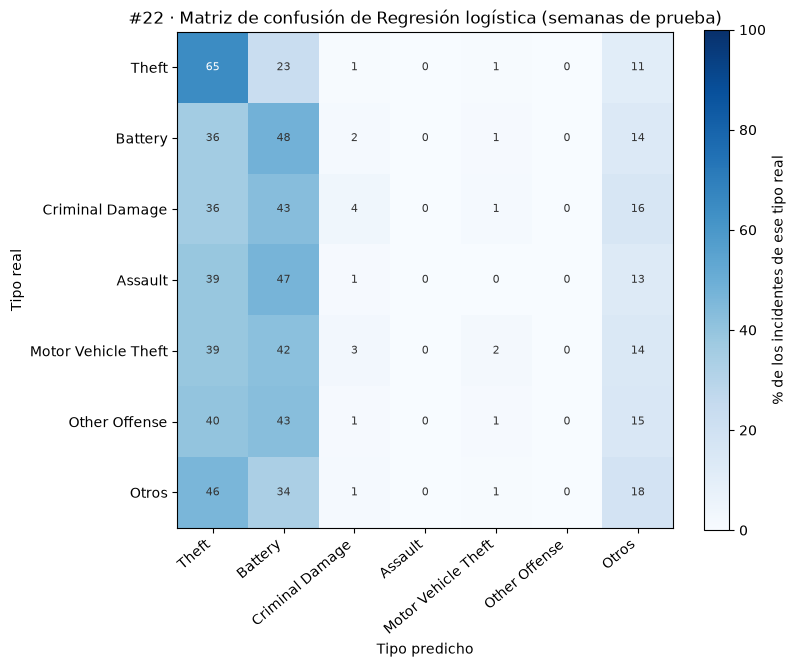

In [12]:
MEJOR = comparacion.loc[list(mejores)].sort_values("F1 macro", ascending=False).index[0]
confusion = detalles[MEJOR][0]
por_fila = confusion.div(confusion.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 6.5))
imagen = ax.imshow(por_fila.values, cmap="Blues", vmin=0, vmax=100)
etiquetas = [c.title() for c in CLASES]
ax.set_xticks(range(len(CLASES)), etiquetas, rotation=40, ha="right")
ax.set_yticks(range(len(CLASES)), etiquetas)
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        valor = por_fila.iat[i, j]
        ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=8, color="white" if valor > 50 else "#333333")
fig.colorbar(imagen, ax=ax, label="% de los incidentes de ese tipo real")
ax.set(title=f"#22 · Matriz de confusión de {MEJOR} (semanas de prueba)", xlabel="Tipo predicho", ylabel="Tipo real")
guardar(fig, "matriz_confusion")
plt.show()

## 5. ¿Anticipa la mezcla de cada zona-turno?

Para patrullar no hace falta acertar cada incidente, sino saber qué mezcla de delitos esperar en una zona-turno. Aquí se compara, para cada zona-turno en las 10 semanas de prueba, la mezcla real contra la que anticipan el modelo (el promedio de sus probabilidades) y la regla del último año. El error es la diferencia promedio entre los porcentajes, en puntos.

In [13]:
modelo_mejor, pred_mejor = predicciones[MEJOR]
reales = (df_prueba.groupBy("beat", "turno").pivot("clase", CLASES).count().fillna(0))
reales = reales.select("beat", "turno", F.expr(" + ".join(f"`{c}`" for c in CLASES)).alias("n"),
                       *[F.col(f"`{c}`").alias(f"real_{i}") for i, c in enumerate(CLASES)])
anticipada = (pred_mejor.groupBy("beat", "turno")
              .agg(*[F.avg(F.element_at("scores", i + 1)).alias(f"modelo_{i}") for i in range(len(CLASES))],
                   *[F.avg(m).alias(f"regla_{i}") for i, m in enumerate(MEZCLA)]))
mezclas = reales.join(anticipada, ["beat", "turno"]).toPandas()
for i in range(len(CLASES)):
    mezclas[f"real_{i}"] = mezclas[f"real_{i}"] / mezclas["n"]

def error_mezcla(prefijo):
    """Diferencia absoluta promedio entre la mezcla real y la anticipada, en puntos porcentuales, ponderada por incidentes."""
    error = sum((mezclas[f"real_{i}"] - mezclas[f"{prefijo}_{i}"]).abs() for i in range(len(CLASES))) / len(CLASES) * 100
    return (error * mezclas["n"]).sum() / mezclas["n"].sum()

for i, p in enumerate(frecuencia_ciudad):
    mezclas[f"ciudad_{i}"] = p
errores = pd.DataFrame({"error de la mezcla (puntos)": {
    f"{MEJOR}": error_mezcla("modelo"),
    "Mezcla de la zona-turno en el último año": error_mezcla("regla"),
    "Mezcla de toda la ciudad": error_mezcla("ciudad")}}).round(2)
print(f"{len(mezclas):,} zonas-turno con incidentes en la prueba")
errores

1,095 zonas-turno con incidentes en la prueba


,error de la mezcla (puntos)
Regresión logística,4.66
Mezcla de la zona-turno en el último año,4.65
Mezcla de toda la ciudad,6.44


In [14]:
ejemplo = mezclas[(mezclas["beat"] == beat_ej) & (mezclas["turno"] == turno_ej)].iloc[0]
tabla_ejemplo = pd.DataFrame({
    "real (%)": [ejemplo[f"real_{i}"] * 100 for i in range(len(CLASES))],
    f"{MEJOR} (%)": [ejemplo[f"modelo_{i}"] * 100 for i in range(len(CLASES))],
    "último año (%)": [ejemplo[f"regla_{i}"] * 100 for i in range(len(CLASES))],
    "ciudad (%)": [ejemplo[f"ciudad_{i}"] * 100 for i in range(len(CLASES))],
}, index=CLASES).round(1)
print(f"Beat {beat_ej}, turno 12-18, semanas {SEMANA_CORTE} a 51 de {ANIO_PRUEBA}: {int(ejemplo['n'])} incidentes")
tabla_ejemplo

Beat 1834, turno 12-18, semanas 42 a 51 de 2025: 210 incidentes


,real (%),Regresión logística (%),último año (%),ciudad (%)
THEFT,55.7,54.4,52.8,24.1
BATTERY,10.0,9.6,10.0,19.1
CRIMINAL DAMAGE,1.9,3.8,4.1,11.9
ASSAULT,5.2,4.5,4.8,9.8
MOTOR VEHICLE THEFT,0.5,2.5,1.9,9.6
OTHER OFFENSE,2.9,2.6,2.4,6.8
OTROS,23.8,22.6,24.0,18.8


### Qué variables pesan

Importancia de las variables en Random Forest (suman 1); el turno, el día y el distrito se suman en un solo valor cada uno. La regresión logística no da una medida equivalente.

In [15]:
nombres = NUMERICAS + [f"{c}={v}" for c, valores in zip(CATEGORICAS, codificacion.stages[0].labelsArray) for v in valores[:-1]]
importancia = pd.Series(predicciones["Random Forest"][0].featureImportances.toArray(), index=nombres)
grupo = importancia.index.map(lambda n: "turno" if n.startswith("turno_etiqueta=") else "día" if n.startswith("dia=")
                              else "distrito" if n.startswith("district=") else n)
importancia.groupby(grupo).sum().sort_values(ascending=False).round(3).to_frame("importancia")

,importancia
mezcla_THEFT,0.245
mezcla_BATTERY,0.132
mezcla_CRIMINAL_DAMAGE,0.099
mezcla_MOTOR_VEHICLE_THEFT,0.076
distrito,0.074
mezcla_OTHER_OFFENSE,0.062
mezcla_ASSAULT,0.060
mezcla_OTROS,0.055
turno,0.046
día,0.046


## 6. Guardar las métricas

In [16]:
tabla_metricas = (comparacion.drop(columns="entrenamiento (s)")
                  .rename(columns={"exactitud (%)": "exactitud", "F1 macro": "f1_macro", "entre los 2 más probables (%)": "top2"})
                  .reset_index())
spark.createDataFrame(tabla_metricas).coalesce(1).write.mode("overwrite").parquet(RUTA_METRICAS)
print("Métricas guardadas en", RUTA_METRICAS)

Métricas guardadas en hdfs:///datalake/curated/metricas_tipo_delito_2022_2025


## Conclusiones

- **El tipo de delito depende sobre todo de dónde.** La mezcla de tipos de la zona-turno en el último año es lo que más pesa en Random Forest (más del 70 % de la importancia junta), y con ella sola la regla simple ya anticipa la mezcla de cada zona-turno con un error de 4.7 puntos, contra 6.4 si se usa la mezcla de toda la ciudad.
- **Ningún clasificador le gana a esa regla.** La regresión logística acierta el 29.4 % de los incidentes, Random Forest el 29.3 % y la regla del tipo más frecuente de la zona-turno el 29.1 %. El F1 macro es el mismo (0.156) y el error de la mezcla también (4.66 contra 4.65). El turno, el día y la semana del año casi no cambian qué tipo ocurre una vez que se sabe la zona.
- **Acertar el tipo de un incidente suelto es difícil.** Con 7 clases, 3 de cada 10 aciertos es poco, pero el tipo real está entre los 2 más probables en casi la mitad de los casos (48.5 %), contra 44 % si siempre se dice "robo o agresión".
- **Las clases chicas casi no se predicen.** ASSAULT, MOTOR VEHICLE THEFT y OTHER OFFENSE tienen F1 cercano a 0: nunca son el tipo más probable en una zona-turno, aunque sí aparecen en la mezcla que el modelo anticipa.
- **Para patrullaje:** sirve para saber qué mezcla de delitos esperar en una zona-turno (por ejemplo, en el beat 1834 de 12 a 18 el modelo anticipa 54 % de robos y se dieron 56 %), y para eso basta la mezcla del último año, sin modelo. No sirve para anticipar el tipo de un incidente concreto.

---

## Evidencia de ejecución en el clúster

In [17]:
sc = spark.sparkContext
print(f"Aplicación: {sc.appName} · {sc.applicationId}")
print(f"Master: {sc.master} · ejecutores activos: {sc._jsc.sc().getExecutorMemoryStatus().size() - 1}")
if not LOCAL:
    print(f"Historial: http://localhost:18080/history/{sc.applicationId}/jobs/")
conf_hadoop = sc._jsc.hadoopConfiguration()
for capa, ruta in [("curated", RUTA_SALIDA), ("curated", RUTA_METRICAS)]:
    ruta_hadoop = spark._jvm.org.apache.hadoop.fs.Path(ruta)
    resumen = ruta_hadoop.getFileSystem(conf_hadoop).getContentSummary(ruta_hadoop)
    print(f"{capa:<10} {resumen.getFileCount():>3} archivos · {resumen.getLength() / 2**20:6.1f} MiB · {ruta}")

Aplicación: tipo-de-delito-cluster · application_1795052165419_0001
Master: yarn · ejecutores activos: 2
Historial: http://localhost:18080/history/application_1795052165419_0001/jobs/
curated      3 archivos ·   13.2 MiB · hdfs:///datalake/curated/tipo_delito_2022_2025
curated      2 archivos ·    0.0 MiB · hdfs:///datalake/curated/metricas_tipo_delito_2022_2025


## Cierre

In [18]:
spark.stop()   # libera la sesión: en la instancia solo cabe una sesión de Spark a la vez